# Part A: three classic NLP methods

In this notebook I build three classic NLP tools from scratch and test them on general-domain text:

1. **Regular expressions:** a small rule-based chatbot ("CodePal") that spots keywords in a message and replies with a canned, encouraging answer. It's the same idea as the 1960s ELIZA program.
2. **A bigram language model:** I train one model on Shakespeare and one on Jane Austen, then use them to guess who wrote a sentence neither model has seen.
3. **Naive Bayes:** a bag-of-words classifier that labels news articles as FAKE or REAL.

The reusable code lives in `src/`. Part B (`02_clinical_text.ipynb`) applies the same tools to clinical notes.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA, RESULTS = ROOT / "data", ROOT / "results"
(RESULTS / "figures").mkdir(parents=True, exist_ok=True)

import nltk
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.model_selection import train_test_split

for pkg in ["gutenberg", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)

from src.regex_patterns import codepal_response, simulate_chat
from src.text_prep import preprocess_text
from src.bigram_model import BigramModel, tokenize_corpus, predict_author
from src.naive_bayes import build_features, train_naive_bayes, predict

SEED = 42
print("NLTK", nltk.__version__)

NLTK 3.9.1


## 1. A rule-based chatbot with regular expressions

CodePal doesn't understand anything. It lowercases the message and checks it against an ordered list of patterns: bugs, errors or crashes, confusing topics, and questions about who it is. The first pattern that matches decides the reply. `\b` word boundaries stop "debug" from matching inside an unrelated word, and anything unmatched gets a general fallback.

A second mode recognises more ways of saying goodbye ("gotta go", "exit", "logout", "see you"). The interactive loop (`chat()` in `src/regex_patterns.py`) waits for keyboard input, so here I play scripted conversations instead.

In [2]:
examples = [
    "I'm stuck on a bug.", "Can you help me debug my code?", "My code won't compile",
    "It keeps crashing", "I don't understand recursion", "Loops are confusing",
    "Who are you?", "Are you human?", "What should I learn next?", "gotta go", "bye",
]
pd.set_option("display.max_colwidth", 90)
pd.DataFrame({
    "message": examples,
    "basic reply": [codepal_response(m) for m in examples],
    "extended reply": [codepal_response(m, extended=True) for m in examples],
})

,message,basic reply,extended reply
0,I'm stuck on a bug.,Debugging can be frustrating. Have you tried printing intermediate results?,Debugging can be frustrating. Have you tried printing intermediate results?
1,Can you help me debug my code?,Debugging can be frustrating. Have you tried printing intermediate results?,Debugging can be frustrating. Have you tried printing intermediate results?
2,My code won't compile,Let's take a deep breath and go step-by-step. What does the error message say?,Let's take a deep breath and go step-by-step. What does the error message say?
3,It keeps crashing,Let's take a deep breath and go step-by-step. What does the error message say?,Let's take a deep breath and go step-by-step. What does the error message say?
4,I don't understand recursion,That's a common hurdle. Would you like a resource that explains it visually?,That's a common hurdle. Would you like a resource that explains it visually?
5,Loops are confusing,That's a common hurdle. Would you like a resource that explains it visually?,That's a common hurdle. Would you like a resource that explains it visually?
6,Who are you?,"I'm CodePal, your friendly code companion designed to support your learning journey.","I'm CodePal, your friendly code companion designed to support your learning journey."
7,Are you human?,"I'm CodePal, your friendly code companion designed to support your learning journey.","I'm CodePal, your friendly code companion designed to support your learning journey."
8,What should I learn next?,Let's tackle it together — what's your next coding challenge?,Let's tackle it together — what's your next coding challenge?
9,gotta go,Let's tackle it together — what's your next coding challenge?,"Happy coding! Remember, every bug is a step forward."


In [3]:
simulate_chat(["Hi there", "I'm debugging a weird issue", "This concept is too hard", "see you", "bye"])

You: Hi there
CodePal: Let's tackle it together — what's your next coding challenge?

You: I'm debugging a weird issue
CodePal: Debugging can be frustrating. Have you tried printing intermediate results?

You: This concept is too hard
CodePal: That's a common hurdle. Would you like a resource that explains it visually?

You: see you
CodePal: Let's tackle it together — what's your next coding challenge?

You: bye
CodePal: Happy coding! Remember, every bug is a step forward.



In [4]:
simulate_chat(["Hi there", "I'm getting an error", "see you", "bye"], extended=True)

You: Hi there
CodePal: Let's tackle it together — what's your next coding challenge?

You: I'm getting an error
CodePal: Let's take a deep breath and go step-by-step. What does the error message say?

You: see you
CodePal: Happy coding! Remember, every bug is a step forward.



In the basic mode "see you" falls through to the fallback reply, and only "bye" ends the chat. In the extended mode "see you" ends it straight away. The rules are easy to read and debug, but they only cover phrasings I thought of in advance.

## 2. Authorship attribution with bigram language models

A bigram model estimates the probability of each word given the word before it, using counts from a training corpus:

$$P(w_i \mid w_{i-1}) = \frac{C(w_{i-1}, w_i) + 1}{C(w_{i-1}) + V}$$

The +1 and +V are add-one (Laplace) smoothing, so a word pair never seen in training still gets a small non-zero probability. $V$ is the training vocabulary size. A sentence's probability is the product of its bigram probabilities. I sum log-probabilities instead to avoid numerical underflow.

I train one model per author on two works each (NLTK's Project Gutenberg sample):
- **Shakespeare:** *Julius Caesar* and *Hamlet*
- **Austen:** *Emma* and *Persuasion*

Then I score sentences from works neither model has seen (*Macbeth* and *Sense and Sensibility*), and the author whose model gives the higher log-probability wins.

In [5]:
from nltk.corpus import gutenberg

def load(name, skip):
    # Skip the title line at the top of each Gutenberg file
    return gutenberg.open(name).read()[skip:]

sh_train = preprocess_text(load("shakespeare-caesar.txt", 62) + load("shakespeare-hamlet.txt", 55))
au_train = preprocess_text(load("austen-emma.txt", 28) + load("austen-persuasion.txt", 35))
sh_test = preprocess_text(load("shakespeare-macbeth.txt", 56))
au_test = preprocess_text(load("austen-sense.txt", 45))

sh_sentences, au_sentences = tokenize_corpus(sh_train), tokenize_corpus(au_train)
models = {"Shakespeare": BigramModel(sh_sentences), "Austen": BigramModel(au_sentences)}

for author, sents in [("Shakespeare", sh_sentences), ("Austen", au_sentences)]:
    m = models[author]
    print(f"{author:12s} sentences: {len(sents):6,}  tokens: {m.n_train_tokens:8,}  "
          f"vocab: {len(m.vocab):6,}  bigram types: {len(m.bigram_counts):7,}")

Shakespeare  sentences:  3,185  tokens:   53,243  vocab:  6,279  bigram types:  32,006
Austen       sentences: 12,015  tokens:  254,136  vocab: 10,861  bigram types:  92,533


In [6]:
test_sentences = {
    "Shakespeare": "when shall we three meet againe in thunder lightning or in raine",
    "Austen": ("elinor this eldest daughter whose advice was so effectual possessed a strength of "
               "understanding and coolness of judgment which qualified her though only nineteen to be "
               "the counsellor of her mother and enabled her frequently to counteract to the advantage "
               "of them all that eagerness of mind in mrs"),
}
for true_author, sentence in test_sentences.items():
    predicted, scores = predict_author(sentence, models)
    print(f"Sentence from {true_author}: '{sentence[:60]}...'")
    for author, lp in scores.items():
        print(f"   log P(sentence | {author:11s}) = {lp:9.4f}")
    print(f"   Most likely author: {predicted}\n")

Sentence from Shakespeare: 'when shall we three meet againe in thunder lightning or in r...'
   log P(sentence | Shakespeare) = -106.9341
   log P(sentence | Austen     ) = -112.4684
   Most likely author: Shakespeare

Sentence from Austen: 'elinor this eldest daughter whose advice was so effectual po...'
   log P(sentence | Shakespeare) = -421.0511
   log P(sentence | Austen     ) = -399.8897
   Most likely author: Austen



### Beyond two sentences

*Added when I prepared this repository.* Two correct guesses don't tell me much, so I also score every held-out sentence of at least five words from *Macbeth* and *Sense and Sensibility*.

In [7]:
rows = []
for true_author, text in [("Shakespeare", sh_test), ("Austen", au_test)]:
    for tokens in tokenize_corpus(text):
        if len(tokens) >= 5:
            predicted, _ = predict_author(" ".join(tokens), models)
            rows.append({"true": true_author, "predicted": predicted})
attr = pd.DataFrame(rows)
attr_acc = (attr.true == attr.predicted).mean()
print(f"Held-out sentences scored: {len(attr):,}")
print(f"Accuracy: {attr_acc:.3f}")
print(pd.crosstab(attr.true, attr.predicted, rownames=["true"], colnames=["predicted"]))

Held-out sentences scored: 5,541
Accuracy: 0.958
predicted    Austen  Shakespeare
true                            
Austen         4435          162
Shakespeare      73          871


## 3. Fake vs real news with Naive Bayes

The dataset has 6,335 news articles labelled FAKE or REAL (George McIntire's fake/real news set; see `data/README.md`). My pipeline:

1. Stratified 70/30 train/test split with a fixed seed.
2. Lowercase, strip punctuation and tokenise each article.
3. Build a **closed vocabulary** from the training articles only. Test words outside it are dropped, so nothing from the test set leaks into training.
4. Represent each article as the set of words it contains, and train NLTK's Naive Bayes classifier.

In [8]:
news = pd.read_csv(DATA / "fake_or_real_news.csv").set_index("Unnamed: 0")
print("Articles:", news.shape[0])
print(news.label.value_counts().to_string())

X_train, X_test, y_train, y_test = train_test_split(
    news.text, news.label, test_size=0.3, random_state=SEED, stratify=news.label)
print(f"\nTrain: {len(X_train):,}   Test: {len(X_test):,}")

Articles: 6335
label
REAL    3171
FAKE    3164

Train: 4,434   Test: 1,901


In [9]:
train_features, test_features, vocabulary = build_features(X_train, y_train, X_test, y_test)
print(f"Closed vocabulary (training only): {len(vocabulary):,} words")

classifier = train_naive_bayes(train_features)
classifier.show_most_informative_features(10)

Closed vocabulary (training only): 77,573 words


Most Informative Features


             frontrunner = True             REAL : FAKE   =    162.7 : 1.0
                caucuses = True             REAL : FAKE   =     62.5 : 1.0
                 fiorina = True             REAL : FAKE   =     57.6 : 1.0
              nominating = True             REAL : FAKE   =     57.6 : 1.0
                   carly = True             REAL : FAKE   =     54.9 : 1.0
                       © = True             FAKE : REAL   =     50.4 : 1.0
                  rubios = True             REAL : FAKE   =     46.9 : 1.0
             presumptive = True             REAL : FAKE   =     45.3 : 1.0
                 boehner = True             REAL : FAKE   =     42.9 : 1.0
                     rky = True             REAL : FAKE   =     37.6 : 1.0


Accuracy: 0.6239   Macro F1: 0.5617

              precision    recall  f1-score   support

        FAKE      0.996     0.248     0.397       949
        REAL      0.571     0.999     0.727       952

    accuracy                          0.624      1901
   macro avg      0.783     0.623     0.562      1901
weighted avg      0.783     0.624     0.562      1901



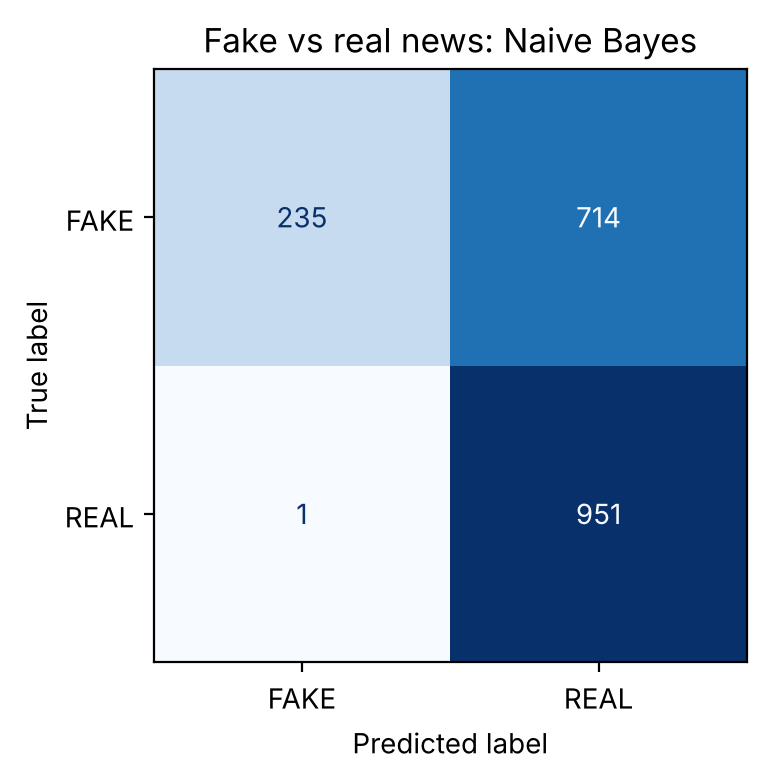

In [10]:
y_true = [label for _, label in test_features]
y_pred = predict(classifier, test_features)

accuracy = metrics.accuracy_score(y_true, y_pred)
macro_f1 = metrics.f1_score(y_true, y_pred, average="macro")
print(f"Accuracy: {accuracy:.4f}   Macro F1: {macro_f1:.4f}\n")
print(metrics.classification_report(y_true, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(4.5, 4))
metrics.ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=["FAKE", "REAL"], cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Fake vs real news: Naive Bayes")
plt.tight_layout()
fig.savefig(RESULTS / "figures" / "partA_fake_news_confusion_matrix.png", dpi=150)
plt.show()

The classifier is lopsided. When it says FAKE it's almost always right, but it labels most fake articles as REAL. One plausible cause is the feature design. I use word *presence* only, and NLTK's classifier scores just the words a document contains, so long articles with many distinct words push the score around a lot. I've kept the result as I originally got it. Part B uses the same pipeline on clinical notes, so this is worth watching there too.

In [11]:
partA = pd.DataFrame([
    {"task": "Authorship attribution (held-out sentences)", "metric": "accuracy", "value": round(attr_acc, 4)},
    {"task": "Fake vs real news (Naive Bayes)", "metric": "accuracy", "value": round(accuracy, 4)},
    {"task": "Fake vs real news (Naive Bayes)", "metric": "macro F1", "value": round(macro_f1, 4)},
])
partA.to_csv(RESULTS / "partA_metrics.csv", index=False)
partA

,task,metric,value
0,Authorship attribution (held-out sentences),accuracy,0.9576
1,Fake vs real news (Naive Bayes),accuracy,0.6239
2,Fake vs real news (Naive Bayes),macro F1,0.5617
